# 04 — Évaluation sur jeux difficiles (emails) — v1

**Pourquoi ce notebook.** Le test du notebook 03 (recall ≈ 0,98, AP ≈ 0,997) vient du **même corpus** que le train : mêmes sources (Enron, Ling, CEAS, Nazario, Nigerian Fraud, SpamAssassin), mêmes gabarits, même époque. Il mesure la capacité à *généraliser à l'intérieur du corpus*, pas à de vrais emails d'aujourd'hui. Ce notebook cherche où le modèle casse.

**Protocole (fixé avant de regarder les résultats)**
- Le modèle, le vectorizer, le **seuil** et la **zone d'incertitude** viennent de `models/email_model.joblib` : **rien n'est réglé ici**. Ajuster quoi que ce soit sur ces jeux les transformerait en jeux de réglage et leur ferait perdre leur valeur.
- Seuils d'alerte écrits à l'avance : un jeu est signalé si le recall passe sous `ALERT_RECALL_FLOOR`, si le taux de faux positifs dépasse `ALERT_FPR_CEIL`, ou si un test de robustesse dégrade une métrique de plus de `ALERT_DROP`.
- Toutes les métriques sont calculées **au seuil figé**. L'average precision et le ROC-AUC ne sont donnés que si le jeu contient les deux classes.

**Quatre familles de jeux difficiles**
- **A. Jeux externes** : des CSV hors des sources du corpus. La section 4 explique le format, retire tout ce qui ressemble à du train, et évalue par défaut le **mini-jeu étendu de 100 emails** (`data/hard/mini_jeu_etendu.csv`) ; vos propres jeux externes s'ajoutent à la même liste.
- **B. Mini-jeu écrit à la main** : 24 emails modernes (phishing poli sans mots de spam, fraude au président, QR code ; légitimes « alarmants » : réinitialisation de mot de passe, alerte de sécurité, formation anti-phishing). Trop petit pour des statistiques : il sert à **lire les erreurs**.
- **C. Tests de robustesse** sur le test d'origine : emails tronqués, URLs retirées, obfuscation par chiffres, texte neutre ajouté, mots-raccourcis injectés. Ils mesurent de combien le score dépend de détails sans rapport avec la menace.
- **D. Tranches** du test d'origine : par longueur et par présence d'URL.

Étapes :
1. Charger le modèle figé et vérifier la chaîne d'inférence
2. Outils d'évaluation
3. Référence : le test d'origine
4. Jeux externes (A)
5. Mini-jeu écrit à la main (B)
6. Tests de robustesse (C)
7. Tranches (D)
8. Synthèse, alertes et sauvegarde

In [1]:
import sys
sys.path.append("..")

import html
import json
import re
import warnings
from pathlib import Path

import joblib
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import scipy.sparse as sp
import seaborn as sns
from sklearn.metrics import average_precision_score, precision_score, roc_auc_score

sns.set_style("whitegrid")
pd.set_option("display.max_colwidth", 90)
pd.set_option("display.width", 200)
warnings.filterwarnings("ignore", category=FutureWarning)

RANDOM_STATE = 42
N_BOOT = 500                 # rééchantillonnages bootstrap pour les intervalles de confiance

# Seuils d'alerte, fixés à l'avance (voir l'introduction)
ALERT_RECALL_FLOOR = 0.90    # recall minimal acceptable sur un jeu difficile
ALERT_FPR_CEIL = 0.10        # taux de faux positifs maximal acceptable
ALERT_DROP = 0.05            # dégradation maximale tolérée dans un test de robustesse

NUM_NAMES = ["body_length", "num_words", "num_urgent_words"]

DATA = Path("../data/processed")
MODELS = Path("../models")
FIGS = Path("../notebooks")

## 1. Charger le modèle figé et vérifier la chaîne d'inférence

On recharge exactement ce que le notebook 03 a sauvegardé. Le point important : pour un email brut, la chaîne est `normalisation → vectorizer → (features numériques si le modèle en utilise) → sélection de colonnes (keep_cols) → modèle`.

**La normalisation est elle-même une source de décalage.** Le corpus d'entraînement est déjà nettoyé en amont (minuscules, ponctuation retirée, URLs et adresses collées en un seul mot, pas de HTML). Un email réel doit subir la même transformation, sinon le vectorizer ne reconnaît pas les mots. `normalize_like_corpus` reproduit cette convention de façon approchée ; la cellule suivante vérifie qu'elle ne déforme pas du texte déjà normalisé, et que la chaîne complète redonne bien les probabilités du notebook 03.

In [2]:
bundle = joblib.load(MODELS / "email_model.joblib")
vectorizer = joblib.load(MODELS / "emails_tfidf_vectorizer.joblib")

THRESHOLD = float(bundle["threshold"])
T_LOW, T_HIGH = (float(v) for v in bundle["uncertainty_band"])
KEEP_COLS = np.asarray(bundle["keep_cols"], dtype=int)
USES_NUMERIC = bool(bundle["numeric_features"])

print(f"Modèle : {bundle['kind']} | composition : {[(type(m).__name__, w) for m, w in zip(bundle['models'], bundle['weights'])]}")
print(f"Seuil opérationnel : {THRESHOLD:.4f} | zone d'incertitude : [{T_LOW:.3f} ; {T_HIGH:.3f}]")
print(f"Colonnes utilisées : {len(KEEP_COLS)} | features numériques : {USES_NUMERIC}")

URL_OR_ADDRESS = re.compile(r"\S*(?:://|www\.|@)\S*")


def normalize_like_corpus(text) -> str:
    """Approche la convention du corpus : minuscules, sans HTML, URLs/adresses collées, ponctuation -> espace."""
    t = html.unescape(str(text))
    t = re.sub(r"<[^>]+>", " ", t).lower().replace("'", "").replace("\u2019", "")
    t = URL_OR_ADDRESS.sub(lambda m: re.sub(r"[^a-z0-9_]", "", m.group(0)), t)
    t = re.sub(r"[^a-z0-9_\s]", " ", t)
    return re.sub(r"\s+", " ", t).strip()


def build_full_matrix(clean_texts) -> sp.csr_matrix:
    """Même matrice que celle du notebook 02 : TF-IDF puis 3 colonnes numériques (log1p, ou zéros si inutilisées)."""
    clean_texts = list(clean_texts)
    X_tfidf = vectorizer.transform(clean_texts)
    if USES_NUMERIC:
        from src.features.email_features import extract_features_batch
        tmp = pd.DataFrame({"subject": "", "body": clean_texts})
        feats = extract_features_batch(tmp)[NUM_NAMES]
        num = sp.csr_matrix(np.log1p(feats.values.astype(float)))
    else:
        num = sp.csr_matrix((X_tfidf.shape[0], len(NUM_NAMES)))
    return sp.hstack([X_tfidf, num]).tocsr()


def predict_proba_bundle(models, weights, X):
    return sum(w * m.predict_proba(X)[:, 1] for m, w in zip(models, weights))


def predict_proba_texts(texts, normalize=True) -> np.ndarray:
    """Probabilité de phishing pour une liste d'emails (bruts si normalize=True)."""
    clean = [normalize_like_corpus(t) if normalize else str(t) for t in texts]
    X = build_full_matrix(clean)[:, KEEP_COLS]
    return predict_proba_bundle(bundle["models"], bundle["weights"], X)

Modèle : logreg | composition : [('LogisticRegression', 1.0)]
Seuil opérationnel : 0.4648 | zone d'incertitude : [0.117 ; 0.929]
Colonnes utilisées : 4914 | features numériques : False


In [3]:
test_df = pd.read_csv(DATA / "emails_test_raw.csv")
y_test = np.load(DATA / "emails_y_test.npy")
assert (test_df["label"].values == y_test).all(), "emails_test_raw.csv et emails_y_test.npy ne correspondent pas"

# Probabilités de référence : matrice du notebook 02 + sélection de colonnes + modèle (comme au notebook 03)
X_test_all = sp.load_npz(DATA / "emails_X_test.npz").tocsr()
p_test = predict_proba_bundle(bundle["models"], bundle["weights"], X_test_all[:, KEEP_COLS])

# 1) La chaîne texte -> probabilité redonne-t-elle ces probabilités ?
p_chain = predict_proba_texts(test_df["text_combined"].iloc[:300], normalize=False)
assert np.allclose(p_chain, p_test[:300], atol=1e-6), "La chaîne d'inférence ne redonne pas les probabilités du notebook 03"
print("Chaîne d'inférence : OK (300 emails, mêmes probabilités que le notebook 03).")

# 2) La normalisation laisse-t-elle intact du texte déjà normalisé ?
sample = test_df["text_combined"].iloc[:2000]
idempotent = np.mean([normalize_like_corpus(t) == t for t in sample])
print(f"Normalisation idempotente sur du texte déjà normalisé : {idempotent:.1%} des emails inchangés")

Chaîne d'inférence : OK (300 emails, mêmes probabilités que le notebook 03).
Normalisation idempotente sur du texte déjà normalisé : 99.4% des emails inchangés


## 2. Outils d'évaluation

`eval_set` calcule, **au seuil figé**, ce qui compte pour la détection :
- **recall** sur les phishings (un phishing classé sûr est le pire cas) ;
- **taux de faux positifs** sur les légitimes (un email légitime bloqué) ;
- **précision**, **average precision** et **ROC-AUC** quand les deux classes sont présentes ;
- la **part d'emails dans la zone d'incertitude** : c'est la part qui partirait vers le LLM dans la cascade. Si elle explose sur un jeu difficile, la cascade coûte plus cher mais joue son rôle ; si elle reste basse alors que le modèle se trompe, il se trompe **avec assurance**, ce qui est le vrai danger.

Les intervalles de confiance à 95 % sont obtenus par bootstrap, séparément pour le recall et le taux de faux positifs.

In [4]:
results = []   # un dictionnaire par jeu évalué


def boot_ci(hits, n_boot=N_BOOT, seed=RANDOM_STATE):
    """IC 95 % bootstrap de la moyenne d'un vecteur 0/1."""
    hits = np.asarray(hits, dtype=float)
    if len(hits) == 0:
        return (np.nan, np.nan)
    rng = np.random.RandomState(seed)
    means = [hits[rng.randint(0, len(hits), len(hits))].mean() for _ in range(n_boot)]
    return tuple(np.percentile(means, [2.5, 97.5]))


def eval_set(y_true, p, t=THRESHOLD):
    y_true = np.asarray(y_true).astype(int)
    p = np.asarray(p, dtype=float)
    pred = (p >= t).astype(int)
    pos, neg = y_true == 1, y_true == 0
    both = bool(pos.any() and neg.any())
    out = {
        "n": int(len(y_true)), "n_phishing": int(pos.sum()), "n_légitime": int(neg.sum()),
        "recall": float(pred[pos].mean()) if pos.any() else np.nan,
        "fpr": float(pred[neg].mean()) if neg.any() else np.nan,
        "précision": float(precision_score(y_true, pred, zero_division=0)) if both and pred.sum() > 0 else np.nan,
        "average_precision": float(average_precision_score(y_true, p)) if both else np.nan,
        "roc_auc": float(roc_auc_score(y_true, p)) if both else np.nan,
        "part_zone_incertitude": float(((p >= T_LOW) & (p <= T_HIGH)).mean()),
    }
    out["recall_ic"] = boot_ci(pred[pos]) if pos.any() else (np.nan, np.nan)
    out["fpr_ic"] = boot_ci(pred[neg]) if neg.any() else (np.nan, np.nan)
    return out


def add_result(name, family, y_true, p):
    r = {"jeu": name, "famille": family, **eval_set(y_true, p)}
    results.append(r)
    return r


def fmt_ci(v, ci):
    return "—" if np.isnan(v) else f"{v:.3f} [{ci[0]:.3f} ; {ci[1]:.3f}]"


def show_results(rows):
    table = pd.DataFrame([{
        "jeu": r["jeu"], "n": r["n"], "phishing": r["n_phishing"],
        "recall [IC95]": fmt_ci(r["recall"], r["recall_ic"]),
        "faux positifs [IC95]": fmt_ci(r["fpr"], r["fpr_ic"]),
        "précision": "—" if np.isnan(r["précision"]) else f"{r['précision']:.3f}",
        "AP": "—" if np.isnan(r["average_precision"]) else f"{r['average_precision']:.4f}",
        "% zone incertaine": f"{r['part_zone_incertitude']:.1%}",
    } for r in rows]).set_index("jeu")
    return table

## 3. Référence : le test d'origine

C'est le chiffre du notebook 03, recalculé avec les mêmes outils que les jeux difficiles, pour que la comparaison soit propre. Tout écart important avec cette ligne est un coût de généralisation.

In [5]:
add_result("test d'origine (référence)", "référence", y_test, p_test)
show_results(results)

,n,phishing,recall [IC95],faux positifs [IC95],précision,AP,% zone incertaine
jeu,,,,,,,
test d'origine (référence),15511,7675,0.983 [0.980 ; 0.986],0.029 [0.026 ; 0.033],0.971,0.9973,10.1%


## 4. Jeux externes (famille A)

C'est la preuve la plus solide : des emails qui n'ont **aucun lien** avec le corpus d'entraînement. Pour en ajouter, remplir `HARD_SETS` ci-dessous avec un dictionnaire par CSV :

```python
{"name": "phishing_recent", "path": "../data/hard/phishing_recent.csv",
 "text_col": "body", "subject_col": "subject",       # subject_col est facultatif
 "label_col": "label", "label_map": {"phishing": 1, "legit": 0}}   # label_map facultatif
```

Un fichier est déjà prévu : `../data/hard/mini_jeu_etendu.csv` (100 emails écrits à la main, 10 catégories de phishing et 10 de légitimes, 5 emails par catégorie). Il porte une colonne `category`, pour lire les résultats **par catégorie** (`category_col`), et une colonne `split` (`dev` / `test`) réservée au notebook 05 : les prompts du LLM se règlent sur `dev`, `test` n'est lu qu'une fois. Ici, le modèle ML n'est pas réglé sur ces emails, donc on évalue les 100.

**Ce que ce jeu n'est pas :** des emails rédigés par une IA, plus propres et plus courts que de vrais messages, et choisis pour être difficiles (fils de discussion détournés, emails très courts, légitimes alarmants). Les taux obtenus mesurent la **fragilité** sur ces situations, pas un taux d'erreur en production ; et à 5 emails par catégorie, un taux de catégorie n'a de valeur qu'indicative.

Règles à respecter pour que le jeu soit vraiment « difficile » et honnête :
- **Hors corpus** : ne pas reprendre Enron, Ling, CEAS, Nazario, Nigerian Fraud ni SpamAssassin (déjà dans le corpus, voir `email_features.py`). Pensez plutôt à du phishing récent (2023 et après : faux partages de documents, fausses factures, fraude au président, QR codes), à du phishing rédigé proprement sans mots de spam, et surtout à des **légitimes qui ressemblent à du phishing** (réinitialisations de mot de passe, alertes de sécurité, factures, newsletters, notifications internes) : ce sont eux qui produisent les faux positifs.
- **Les deux classes** si possible : un jeu 100 % phishing ne mesure que le recall, un jeu 100 % légitime que le taux de faux positifs.
- **Étiquettes fiables** : on a déjà vu au notebook 01 qu'un corpus public peut contenir des étiquettes douteuses (les newsletters CNN).

Le code normalise les textes comme le corpus, puis **retire tout email dont les 20 premiers mots existent déjà dans le corpus nettoyé** (même règle que `dup_group` au notebook 01) : sans cela, un recouvrement avec le train gonflerait les scores.

In [6]:
HARD_SETS = [
    # Jeu étendu de 100 emails écrits à la main (10 catégories de phishing, 10 de légitimes).
    # Colonne "split" : "dev" pour régler les prompts du notebook 05, "test" pour la mesure finale ; ici, on évalue tout.
    {"name": "mini-jeu étendu (100)", "path": "../data/hard/mini_jeu_etendu.csv",
     "text_col": "text", "label_col": "label", "category_col": "category"},
    # Ajouter ici vos jeux externes, par exemple :
    # {"name": "mon_jeu_externe", "path": "../data/hard/mon_jeu.csv", "text_col": "text", "label_col": "label"},
]
category_tables = {}


def prefix_key(text, n_words=20):
    return " ".join(str(text).split()[:n_words])


def load_hard_set(spec):
    raw = pd.read_csv(spec["path"])
    text = raw[spec["text_col"]].fillna("").astype(str)
    if spec.get("subject_col"):
        text = raw[spec["subject_col"]].fillna("").astype(str) + " " + text
    label = raw[spec["label_col"]]
    if spec.get("label_map"):
        label = label.map(spec["label_map"])
    out = pd.DataFrame({"text": text, "label": label})
    if spec.get("category_col"):
        out["category"] = raw[spec["category_col"]].values
    out = out.dropna(subset=["label"])
    out["label"] = out["label"].astype(int)
    out["clean"] = out["text"].apply(normalize_like_corpus)
    return out[out["clean"].str.len() > 0].reset_index(drop=True)


if not HARD_SETS:
    print("Aucun jeu externe configuré : section ignorée (les familles B, C et D ne dépendent pas de données externes).")
else:
    corpus_keys = set(prefix_key(t) for t in pd.read_csv(DATA / "emails_clean.csv", usecols=["text_combined"])["text_combined"])
    for spec in HARD_SETS:
        if not Path(spec["path"]).exists():
            print(f"[{spec['name']}] fichier introuvable : {spec['path']} -> ignoré")
            continue
        hs = load_hard_set(spec)
        overlap = hs["clean"].apply(prefix_key).isin(corpus_keys)
        print(f"[{spec['name']}] {len(hs)} emails, dont {int(overlap.sum())} retirés (début identique à un email du corpus)")
        hs = hs[~overlap].reset_index(drop=True)
        if hs.empty:
            continue
        p = predict_proba_bundle(bundle["models"], bundle["weights"], build_full_matrix(hs["clean"])[:, KEEP_COLS])
        add_result(spec["name"], "externe", hs["label"].values, p)
        if "category" in hs.columns:
            hs["signalé"] = (p >= THRESHOLD).astype(int)
            hs["dans_zone"] = ((p >= T_LOW) & (p <= T_HIGH)).astype(int)
            cat = (hs.groupby(["label", "category"])
                     .agg(n=("signalé", "size"), signalés=("signalé", "sum"), dans_zone=("dans_zone", "sum"))
                     .reset_index())
            cat["classe"] = cat["label"].map({1: "phishing", 0: "légitime"})
            cat["taux"] = (cat["signalés"] / cat["n"]).round(2)
            category_tables[spec["name"]] = cat[["classe", "category", "n", "signalés", "taux", "dans_zone"]]
    print()
    print(show_results([r for r in results if r["famille"] == "externe"]))
    for name, cat in category_tables.items():
        print(f"\nPar catégorie : {name}")
        print("(taux = recall pour une catégorie de phishing, taux de faux positifs pour une catégorie légitime ;")
        print(" dans_zone = emails de la catégorie qui partiraient vers le LLM)")
        print(cat.to_string(index=False))

[mini-jeu étendu (100)] 100 emails, dont 0 retirés (début identique à un email du corpus)

                         n  phishing          recall [IC95]   faux positifs [IC95] précision      AP % zone incertaine
jeu                                                                                                                   
mini-jeu étendu (100)  100        50  0.820 [0.720 ; 0.920]  0.580 [0.460 ; 0.720]     0.586  0.7229             42.0%

Par catégorie : mini-jeu étendu (100)
(taux = recall pour une catégorie de phishing, taux de faux positifs pour une catégorie légitime ;
 dans_zone = emails de la catégorie qui partiraient vers le LLM)
  classe                      category  n  signalés  taux  dans_zone
légitime            agenda_rendez_vous  5         1   0.2          3
légitime                   avis_banque  5         5   1.0          2
légitime            commande_livraison  5         4   0.8          3
légitime                court_legitime  5         2   0.4          2
légi

## 5. Mini-jeu écrit à la main (famille B)

24 emails rédigés pour ce notebook, **sans lien avec le corpus** : 12 phishings modernes et 12 légitimes. Ils ne ressemblent pas aux spams « classiques » du corpus (pas de montres, pas de pilules) : phishing poli, fraude au président sans lien ni pièce jointe, faux colis, faux partage de document, faux QR code ; et du côté légitime, tout ce qui contient des mots qui font peur (mot de passe, sécurité, facture, vérifier).

**Un détail de format compte :** dans le corpus, le sujet est fusionné au début du texte sans étiquette, et le mot `subject` y est un indice de légitime (emails Enron transférés). Le préfixe `Subject:` des emails ci-dessous est donc retiré avant de les passer au modèle ; le laisser fausserait le test.

**Limite à ne pas oublier : 24 emails ne permettent aucune conclusion statistique** (les intervalles de confiance sont énormes). L'intérêt est de voir **lesquels** sont mal classés et **pourquoi**. Ces textes sont de ma rédaction : ils sont plus nets et plus courts que de vrais emails, et l'auteur de ce notebook connaît le modèle. Ce n'est donc pas un substitut aux jeux externes de la section 4.

In [7]:
HAND = [
    # (id, catégorie, label, texte)  ·  label 1 = phishing, 0 = légitime
    ("P01", "phishing poli (identifiants)", 1, "Subject: Action needed: your mailbox storage is almost full. Hello, your mailbox has reached 98% of its quota and new messages may be rejected. To keep receiving mail, please sign in to the portal below and confirm your account within 24 hours. https://mail-storage-verify.example-portal.com/login Regards, IT Support Team"),
    ("P02", "phishing ciblé sans mots de spam", 1, "Subject: Updated payroll details. Hi, HR has migrated payroll to a new platform. Please review and confirm your direct deposit information before Friday so your next salary is not delayed: https://payroll-update.example-hr.net/confirm Thank you, Human Resources"),
    ("P03", "phishing poli (facture)", 1, "Subject: Invoice 48213 overdue. Dear customer, our records show invoice 48213 for $2,480.00 is past due. A copy is attached. Please open the document to review the payment instructions and settle the balance today to avoid late fees. Accounts Receivable"),
    ("P04", "phishing poli (partage de document)", 1, "Subject: Document shared with you. Maria shared 'Q3 budget review' with you. Open the document using your work email to view and comment: https://docs-share-view.example-cloud.org/d/Q3budget Note: this link will expire in 48 hours."),
    ("P05", "fraude au président (sans lien)", 1, "Subject: Quick favor. Hi, are you at your desk? I am in a meeting and cannot take calls. I need you to purchase some gift cards for a client today and I will reimburse you. Reply as soon as you see this. Thanks, David"),
    ("P06", "phishing poli (colis)", 1, "Subject: Your parcel could not be delivered. We attempted to deliver your package today but the address was incomplete. Confirm your address and pay a small redelivery fee of $1.99 here: http://redeliver-parcel.example-track.com/pay otherwise it will be returned to the sender."),
    ("P07", "phishing poli (alerte banque)", 1, "Subject: Unusual sign-in detected on your account. We noticed a login from a new device in another country. If this was not you, secure your account now by verifying your identity: https://secure-bank-verify.example-login.com Customer Security Department"),
    ("P08", "phishing poli (mot de passe)", 1, "Subject: Password expires today. Your network password expires in 3 hours. Click below to keep your current password and avoid being locked out of email and VPN. Keep password: https://sso-password-keep.example-auth.com IT Service Desk"),
    ("P09", "phishing poli (remboursement)", 1, "Subject: You are eligible for a tax refund. After the latest review of your tax return, you are eligible to receive a refund of $612.40. Submit the refund request form and your bank details through the secure link: https://tax-refund-claim.example-gov.net"),
    ("P10", "fraude classique (témoin)", 1, "Subject: Beneficiary notification. I am a lawyer representing the estate of a deceased client who shares your surname. The estate holds funds of 4.5 million dollars and you may be entitled to claim them as next of kin. Please reply with your full name and phone number so I can send the details. Barrister J. Whitmore"),
    ("P11", "fausse offre d'emploi", 1, "Subject: Remote assistant position. We reviewed your profile and would like to offer you a part time remote assistant role paying 450 dollars a week. We will send a check to cover your equipment. Please reply with your address and the name of your bank to get started. Recruitment team"),
    ("P12", "phishing QR code", 1, "Subject: Mandatory security update. To comply with the new security policy, all employees must re-register their authenticator. Scan the QR code in the attached PDF with your phone before the end of the day. Failure to comply will suspend your access. Security Operations"),
    ("L01", "légitime transactionnel alarmant", 0, "Subject: Reset your password. We received a request to reset the password for your account. Use the link below within 60 minutes to choose a new password. If you did not make this request, you can safely ignore this email. https://accounts.example.com/reset?token=abc123 The Support Team"),
    ("L02", "légitime transactionnel alarmant", 0, "Subject: New sign-in to your account. A new sign-in was detected on a Windows laptop near Lyon, France. If this was you, no action is needed. If not, review your recent activity and change your password from your account settings page. Account Security"),
    ("L03", "légitime transactionnel (facture)", 0, "Subject: Your invoice for September. Hello, your invoice 10492 for 39.00 EUR is attached. The amount will be charged automatically to your card on file on the 5th. You can download receipts anytime from your billing page. Thank you for your business."),
    ("L04", "légitime transactionnel (colis)", 0, "Subject: Your order has shipped. Good news, order 88214 is on its way and should arrive between Tuesday and Thursday. You can follow the delivery with the tracking number below. Contact customer service if you have any question."),
    ("L05", "légitime transactionnel (banque)", 0, "Subject: Your monthly statement is ready. Your statement for September is now available in online banking. For your security we never include account details in email. Sign in through our official app to view it."),
    ("L06", "légitime marketing", 0, "Subject: Autumn sale starts now. Up to 40% off selected jackets and boots until Sunday. Free returns on all orders. You are receiving this email because you subscribed to our newsletter. Unsubscribe at any time from your preferences page."),
    ("L07", "légitime notification interne", 0, "Subject: Scheduled maintenance on Saturday. The mail server will be offline between 2 and 4 am on Saturday for scheduled maintenance. No action is required on your side. Contact the helpdesk by phone if you have questions. IT Operations"),
    ("L08", "légitime notification interne", 0, "Subject: Open enrollment reminder. Open enrollment for benefits closes on October 31. Review your options on the intranet and submit your choices before the deadline. The HR team is available on Tuesday afternoons for questions."),
    ("L09", "légitime échange entre collègues", 0, "Subject: Re: slides for Thursday. Thanks for sending the draft. I made a few edits to slide 6 and added the revenue chart. Can we go through it together tomorrow morning before the client call? Cheers, Anna"),
    ("L10", "légitime invitation", 0, "Subject: Invitation: project sync. You are invited to the weekly project sync on Wednesday at 10:30. Agenda: milestones, risks, budget. Join with the video link in the calendar event."),
    ("L11", "légitime vocabulaire de phishing", 0, "Subject: Phishing awareness training. This month's training covers how to spot phishing emails: check the sender address, hover over links before clicking, and never share your password. Report suspicious messages with the report button. Training takes about 15 minutes."),
    ("L12", "légitime transactionnel alarmant", 0, "Subject: Confirm your email address. Welcome! Please confirm your email address to finish creating your account. Click the button below. If you did not sign up, simply ignore this message. https://app.example.com/confirm/9f8e7d"),
]
hand = pd.DataFrame(HAND, columns=["id", "catégorie", "label", "texte"])
# Dans le corpus, le sujet est fusionné au début du texte SANS étiquette ; le mot « subject » y est un indice de légitime
# (emails Enron transférés). On retire donc le préfixe « Subject: » avant le modèle, sinon on fausserait le test.
hand["texte_modele"] = hand["texte"].str.replace(r"^Subject:\s*", "", regex=True)
hand["p"] = predict_proba_texts(hand["texte_modele"])
hand["prédit"] = (hand["p"] >= THRESHOLD).astype(int)
hand["zone"] = np.where((hand["p"] >= T_LOW) & (hand["p"] <= T_HIGH), "incertain", "tranché")

add_result("mini-jeu à la main (24)", "main", hand["label"].values, hand["p"].values)
add_result("  dont phishing modernes (P01-P12)", "main", hand.loc[hand["label"] == 1, "label"].values, hand.loc[hand["label"] == 1, "p"].values)
add_result("  dont légitimes difficiles (L01-L12)", "main", hand.loc[hand["label"] == 0, "label"].values, hand.loc[hand["label"] == 0, "p"].values)
show_results([r for r in results if r["famille"] == "main"])

,n,phishing,recall [IC95],faux positifs [IC95],précision,AP,% zone incertaine
jeu,,,,,,,
mini-jeu à la main (24),24,12,0.750 [0.500 ; 0.960],0.417 [0.167 ; 0.710],0.643,0.7094,29.2%
dont phishing modernes (P01-P12),12,12,0.750 [0.500 ; 0.960],—,—,—,33.3%
dont légitimes difficiles (L01-L12),12,0,—,0.417 [0.167 ; 0.710],—,—,25.0%


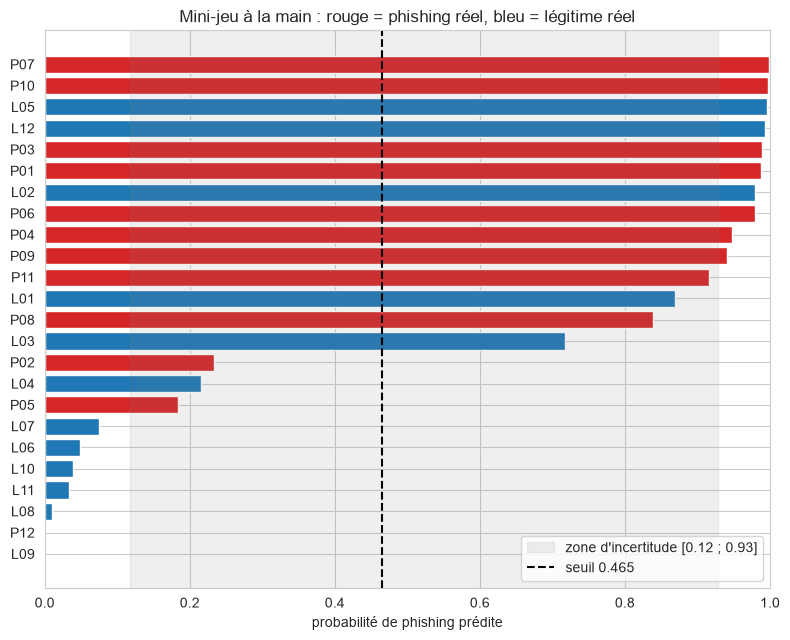

In [ ]:
order = hand.sort_values("p").reset_index(drop=True)
fig, ax = plt.subplots(figsize=(8, 6.5))
ax.barh(range(len(order)), order["p"], color=np.where(order["label"] == 1, "tab:red", "tab:blue"))
ax.axvspan(T_LOW, T_HIGH, color="gray", alpha=0.12, label=f"zone d'incertitude [{T_LOW:.2f} ; {T_HIGH:.2f}]")
ax.axvline(THRESHOLD, color="black", linestyle="--", label=f"seuil {THRESHOLD:.3f}")
ax.set_yticks(range(len(order)))
ax.set_yticklabels(order["id"])
ax.set_xlim(0, 1)
ax.set_xlabel("probabilité de phishing prédite")
ax.set_title("Mini-jeu à la main : rouge = phishing réel, bleu = légitime réel")
ax.legend(loc="lower right")
plt.tight_layout()
plt.show()

### Lire les erreurs

Pour chaque email mal classé **ou** dans la zone d'incertitude, on affiche les mots qui ont poussé la décision (coefficient de la régression logistique × poids TF-IDF du mot). C'est la façon la plus directe de voir si le modèle se trompe pour une bonne raison (le texte est ambigu) ou pour une mauvaise (un mot sans rapport, un mot de source).

In [9]:
lr = next((m for m in bundle["models"] if hasattr(m, "coef_")), None)
names_use = np.array(bundle["feature_names"])


def explain(text, k=5):
    """Mots qui poussent vers phishing / légitime (régression logistique simple uniquement)."""
    if lr is None:
        return "(explication indisponible : le modèle n'est pas une régression logistique simple)"
    X = build_full_matrix([normalize_like_corpus(text)])[:, KEEP_COLS]
    contrib = X.multiply(lr.coef_.ravel()).tocsr()
    idx, val = contrib.indices, contrib.data
    order_ = np.argsort(val)
    to_phish = [str(names_use[idx[i]]) for i in order_[::-1][:k] if val[i] > 0]
    to_legit = [str(names_use[idx[i]]) for i in order_[:k] if val[i] < 0]
    return f"vers PHISHING : {to_phish} | vers LÉGITIME : {to_legit}"


problems = hand[(hand["prédit"] != hand["label"]) | (hand["zone"] == "incertain")].sort_values("p")
print(f"{len(problems)} emails sur {len(hand)} sont mal classés ou dans la zone d'incertitude.\n")
for _, r in problems.iterrows():
    verdict = "OK" if r["prédit"] == r["label"] else ("PHISHING MANQUÉ" if r["label"] == 1 else "FAUX POSITIF")
    print(f"{r['id']} [{r['catégorie']}] p={r['p']:.3f} -> {verdict} ({r['zone']})")
    print("   ", explain(r["texte_modele"]))

11 emails sur 24 sont mal classés ou dans la zone d'incertitude.

P12 [phishing QR code] p=0.000 -> PHISHING MANQUÉ (tranché)
    vers PHISHING : ['scan', 'security', 'new'] | vers LÉGITIME : ['employees', 'attached', 'policy', 'register', 'code']
P05 [fraude au président (sans lien)] p=0.184 -> PHISHING MANQUÉ (incertain)
    vers PHISHING : ['reply', 'soon', 'cards', 'calls', 'client'] | vers LÉGITIME : ['thanks', 'meeting', 'david', 'gift', 'desk']
L04 [légitime transactionnel (colis)] p=0.216 -> OK (incertain)
    vers PHISHING : ['shipped', 'delivery', 'tracking', 'arrive', 'order'] | vers LÉGITIME : ['question', 'customer service', 'tuesday', 'thursday', 'way']
P02 [phishing ciblé sans mots de spam] p=0.234 -> PHISHING MANQUÉ (incertain)
    vers PHISHING : ['confirm', 'details', 'salary', 'information', 'deposit'] | vers LÉGITIME : ['friday', 'direct', 'resources', 'thank', 'updated']
L03 [légitime transactionnel (facture)] p=0.717 -> FAUX POSITIF (incertain)
    vers PHISHING :

## 6. Tests de robustesse (famille C)

On part du **test d'origine** (15 511 emails, étiquettes fiables) et on le déforme de façon contrôlée. Chaque test répond à une question précise :

| Test | Question |
|---|---|
| tronqué à 30 mots / à 12 mots | Le modèle tient-il sur des emails courts (SMS-like, aperçu d'email) ? |
| URLs retirées | Dépend-il des liens ? Les phishings modernes cachent souvent le lien derrière un bouton. |
| obfuscation par chiffres | Une attaque triviale (`ph1sh1ng`, `acc0unt`) casse-t-elle le modèle ? |
| texte neutre ajouté (tous) | Un paragraphe poli collé à la fin fait-il passer un phishing ? Un légitime devient-il suspect ? |
| **mots-raccourcis ajoutés aux phishings** | Le modèle croit-il « légitime » dès qu'il voit des mots d'Enron ou de listes de diffusion ? Mesure directe du raccourci de source. |
| **pied de newsletter ajouté aux légitimes** | Des mots courants dans les newsletters (`remove`, `unsubscribe`, `http`…) font-ils basculer des légitimes ? |

Les emails étant déjà normalisés, on n'applique pas `normalize_like_corpus` ici (`normalize=False`). On compare chaque test à la **base sur les mêmes emails**.

In [10]:
texts = test_df["text_combined"].fillna("")
is_phish, is_legit = (y_test == 1), (y_test == 0)

LEET = str.maketrans("oia", "014")
PAD = "thank you for your time please let me know if you have any questions or need anything else best regards"
INJECT_LEGIT_WORDS = "houston daren corp employees mailing list wrote thanks forwarded university"
NEWSLETTER_FOOTER = "to remove yourself from this list click unsubscribe http investment statements quality"


def truncate(n):
    return lambda s: s.str.split().str[:n].str.join(" ")


def drop_urls(s):
    return s.apply(lambda t: " ".join(w for w in t.split() if not w.startswith(("http", "www"))))


def leet(s, frac=0.15):
    rng = np.random.RandomState(RANDOM_STATE)
    return s.apply(lambda t: " ".join(w.translate(LEET) if rng.rand() < frac else w for w in t.split()))


# (nom, transformation, classes concernées)
STRESS = [
    ("tronqué à 30 mots", truncate(30), "tous"),
    ("tronqué à 12 mots", truncate(12), "tous"),
    ("URLs retirées", drop_urls, "tous"),
    ("obfuscation par chiffres (15 % des mots)", leet, "tous"),
    ("texte neutre ajouté", lambda s: s + " " + PAD, "tous"),
    ("mots-raccourcis ajoutés aux phishings", lambda s: s + " " + INJECT_LEGIT_WORDS, "phishing"),
    ("pied de newsletter ajouté aux légitimes", lambda s: s + " " + NEWSLETTER_FOOTER, "légitime"),
]

rows = []
for name, fn, scope in STRESS:
    mask = is_phish if scope == "phishing" else is_legit if scope == "légitime" else np.ones(len(y_test), bool)
    p_new = predict_proba_texts(fn(texts[mask]), normalize=False)
    p_old = p_test[mask]
    yy = y_test[mask]
    row = {"test": name, "n": int(mask.sum())}
    if (yy == 1).any():
        row["recall avant"] = (p_old[yy == 1] >= THRESHOLD).mean()
        row["recall après"] = (p_new[yy == 1] >= THRESHOLD).mean()
        row["Δ recall"] = row["recall après"] - row["recall avant"]
    if (yy == 0).any():
        row["fpr avant"] = (p_old[yy == 0] >= THRESHOLD).mean()
        row["fpr après"] = (p_new[yy == 0] >= THRESHOLD).mean()
        row["Δ fpr"] = row["fpr après"] - row["fpr avant"]
    row["zone incertaine après"] = ((p_new >= T_LOW) & (p_new <= T_HIGH)).mean()
    rows.append(row)
    print(f"{name:<45} fait", flush=True)

stress_df = pd.DataFrame(rows).set_index("test")
stress_df.round(4)

tronqué à 30 mots                             fait
tronqué à 12 mots                             fait
URLs retirées                                 fait
obfuscation par chiffres (15 % des mots)      fait
texte neutre ajouté                           fait
mots-raccourcis ajoutés aux phishings         fait
pied de newsletter ajouté aux légitimes       fait


,n,recall avant,recall après,Δ recall,fpr avant,fpr après,Δ fpr,zone incertaine après
test,,,,,,,,
tronqué à 30 mots,15511,0.9827,0.9726,-0.0100,0.0288,0.0755,0.0467,0.1870
tronqué à 12 mots,15511,0.9827,0.9539,-0.0288,0.0288,0.1715,0.1427,0.3023
URLs retirées,15511,0.9827,0.9807,-0.0020,0.0288,0.0279,-0.0009,0.1040
obfuscation par chiffres (15 % des mots),15511,0.9827,0.9810,-0.0017,0.0288,0.0329,0.0041,0.1125
texte neutre ajouté,15511,0.9827,0.7494,-0.2332,0.0288,0.0051,-0.0237,0.1983
mots-raccourcis ajoutés aux phishings,7675,0.9827,0.1866,-0.7961,NaN,NaN,NaN,0.1706
pied de newsletter ajouté aux légitimes,7836,NaN,NaN,NaN,0.0288,0.2906,0.2617,0.3060


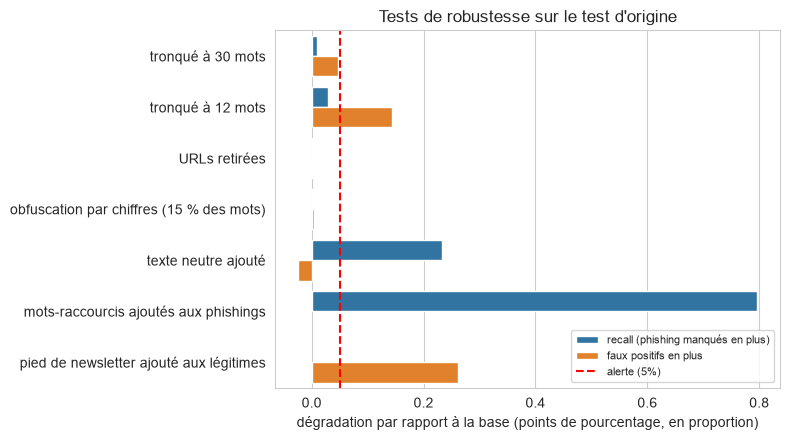

,alerte
test,
tronqué à 30 mots,ok
tronqué à 12 mots,ALERTE
URLs retirées,ok
obfuscation par chiffres (15 % des mots),ok
texte neutre ajouté,ALERTE
mots-raccourcis ajoutés aux phishings,ALERTE
pied de newsletter ajouté aux légitimes,ALERTE


In [ ]:
stress_df["alerte"] = (
    (stress_df.get("Δ recall", 0).fillna(0) < -ALERT_DROP) | (stress_df.get("Δ fpr", 0).fillna(0) > ALERT_DROP)
).map({True: "ALERTE", False: "ok"})

fig, ax = plt.subplots(figsize=(8, 4.5))
plot_rows = []
for name, r in stress_df.iterrows():
    if not np.isnan(r.get("Δ recall", np.nan)):
        plot_rows.append((name, "recall (phishing manqués en plus)", -r["Δ recall"]))
    if not np.isnan(r.get("Δ fpr", np.nan)):
        plot_rows.append((name, "faux positifs en plus", r["Δ fpr"]))
plot_df = pd.DataFrame(plot_rows, columns=["test", "mesure", "dégradation"])
sns.barplot(data=plot_df, y="test", x="dégradation", hue="mesure", ax=ax)
ax.axvline(ALERT_DROP, color="red", linestyle="--", label=f"alerte ({ALERT_DROP:.0%})")
ax.set_xlabel("dégradation par rapport à la base (points de pourcentage, en proportion)")
ax.set_ylabel("")
ax.set_title("Tests de robustesse sur le test d'origine")
ax.legend(loc="lower right", fontsize=8)
plt.tight_layout()
plt.show()
stress_df[["alerte"]]

## 7. Tranches du test d'origine (famille D)

Une moyenne peut cacher une catégorie où le modèle est mauvais. On découpe le test d'origine par **longueur** (quartiles du nombre de mots) et par **présence d'une URL** (un mot qui commence par `http` ou `www`), et on lit les métriques tranche par tranche. Les tranches sont définies à partir des textes seuls, jamais des étiquettes.

In [12]:
n_words = texts.str.split().str.len()
length_bucket = pd.qcut(n_words, 4, duplicates="drop")
has_url = texts.apply(lambda t: any(w.startswith(("http", "www")) for w in t.split()))

slices = []
for label, mask in [(f"longueur {iv}", (length_bucket == iv).values) for iv in length_bucket.cat.categories] + \
                   [("avec URL", has_url.values), ("sans URL", ~has_url.values)]:
    r = eval_set(y_test[mask], p_test[mask])
    slices.append({"tranche": label, "n": r["n"], "% phishing": f"{y_test[mask].mean():.1%}",
                   "recall": round(r["recall"], 4), "faux positifs": round(r["fpr"], 4),
                   "précision": round(r["précision"], 4), "% zone incertaine": f"{r['part_zone_incertitude']:.1%}"})
    results.append({"jeu": f"tranche : {label}", "famille": "tranche", **r})
pd.DataFrame(slices).set_index("tranche")

,n,% phishing,recall,faux positifs,précision,% zone incertaine
tranche,,,,,,
"longueur (0.999, 38.0]",4023,71.6%,0.9830,0.0665,0.9739,14.2%
"longueur (38.0, 75.0]",3768,57.2%,0.9879,0.0279,0.9793,9.7%
"longueur (75.0, 168.0]",3858,32.6%,0.9706,0.0212,0.9569,9.2%
"longueur (168.0, 13986.0]",3862,35.7%,0.9848,0.0201,0.9645,6.9%
avec URL,7320,51.8%,0.9868,0.0298,0.9727,9.6%
sans URL,8191,47.4%,0.9786,0.0281,0.9691,10.5%


## 8. Synthèse, alertes et sauvegarde

Tout est rassemblé dans un seul tableau, avec les alertes calculées par les **seuils fixés dans l'introduction** (pas de seuil ajusté après coup). Les tests de robustesse ont leur propre règle (`ALERT_DROP`) ; les petits jeux (moins de 50 emails) sont signalés comme indicatifs.

In [13]:
summary_rows = [r for r in results if r["famille"] in ("référence", "externe", "main", "tranche")]
print(show_results(summary_rows).to_string())

alerts = []
for r in results:
    if r["famille"] not in ("externe", "main", "tranche"):
        continue
    small = r["n"] < 50
    tag = " (jeu < 50 emails : indicatif)" if small else ""
    if r["n_phishing"] > 0 and r["recall"] < ALERT_RECALL_FLOOR:
        alerts.append(f"{r['jeu']} : recall {r['recall']:.3f} < {ALERT_RECALL_FLOOR}{tag}")
    if r["n_légitime"] > 0 and r["fpr"] > ALERT_FPR_CEIL:
        alerts.append(f"{r['jeu']} : faux positifs {r['fpr']:.3f} > {ALERT_FPR_CEIL}{tag}")
for name, r in stress_df.iterrows():
    if r["alerte"] == "ALERTE":
        alerts.append(f"robustesse « {name} » : dégradation > {ALERT_DROP:.0%}")

print()
print("ALERTES" if alerts else "Aucune alerte.")
for a in alerts:
    print(" -", a)

                                           n  phishing          recall [IC95]   faux positifs [IC95] précision      AP % zone incertaine
jeu                                                                                                                                     
test d'origine (référence)             15511      7675  0.983 [0.980 ; 0.986]  0.029 [0.026 ; 0.033]     0.971  0.9973             10.1%
mini-jeu étendu (100)                    100        50  0.820 [0.720 ; 0.920]  0.580 [0.460 ; 0.720]     0.586  0.7229             42.0%
mini-jeu à la main (24)                   24        12  0.750 [0.500 ; 0.960]  0.417 [0.167 ; 0.710]     0.643  0.7094             29.2%
  dont phishing modernes (P01-P12)        12        12  0.750 [0.500 ; 0.960]                      —         —       —             33.3%
  dont légitimes difficiles (L01-L12)     12         0                      —  0.417 [0.167 ; 0.710]         —       —             25.0%
tranche : longueur (0.999, 38.0]        4

In [14]:
def clean(v):
    if isinstance(v, (tuple, list)):
        return [clean(x) for x in v]
    if isinstance(v, (float, np.floating)):
        return None if np.isnan(v) else round(float(v), 4)
    if isinstance(v, (np.integer,)):
        return int(v)
    return v


report = {
    "modèle": bundle["kind"],
    "seuil_opérationnel": round(THRESHOLD, 4),
    "zone_incertitude": [round(T_LOW, 4), round(T_HIGH, 4)],
    "seuils_alerte": {"recall_min": ALERT_RECALL_FLOOR, "fpr_max": ALERT_FPR_CEIL, "dégradation_max": ALERT_DROP},
    "jeux": [{k: clean(v) for k, v in r.items()} for r in results],
    "robustesse": json.loads(stress_df.reset_index().to_json(orient="records", force_ascii=False)),
    "mini_jeu_main": hand[["id", "catégorie", "label", "p", "prédit", "zone"]].round(4).to_dict(orient="records"),
    "catégories": {k: json.loads(v.to_json(orient="records", force_ascii=False)) for k, v in category_tables.items()},
    "alertes": alerts,
}
with open(MODELS / "email_hard_eval.json", "w", encoding="utf-8") as f:
    json.dump(report, f, ensure_ascii=False, indent=2)
print("Sauvegardé :", MODELS / "email_hard_eval.json")

Sauvegardé : ..\models\email_hard_eval.json


## Conclusion à compléter avec vos chiffres

À remplir une fois le notebook exécuté, à partir du tableau de synthèse et de `models/email_hard_eval.json`. Trois questions, trois phrases :

- **Le modèle généralise-t-il ?** Comparer le recall et le taux de faux positifs des jeux difficiles à la ligne « test d'origine ». Un écart de plus de quelques points est le coût réel de la généralisation ; le dire tel quel, y compris s'il est grand. Si aucun jeu externe n'a été utilisé, l'écrire : « la généralisation hors corpus n'a pas été mesurée sur des données externes ; seuls un mini-jeu de 24 emails et des tests de robustesse l'indiquent ».
- **Où casse-t-il ?** Citer les alertes déclenchées et les emails du mini-jeu mal classés, avec les mots responsables (cellule « Lire les erreurs »). Les catégories les plus fragiles sont attendues du côté des légitimes qui ressemblent à du phishing (faux positifs) et du phishing poli sans mots de spam (phishings manqués).
- **La cascade ML → LLM compense-t-elle ?** Regarder la part de la zone d'incertitude sur les jeux difficiles et, surtout, **si les erreurs tombent dans la zone** (le LLM peut les rattraper) ou **en dehors** (le ML se trompe avec assurance, la cascade ne les voit pas). Cette dernière situation est la limite principale à signaler.

**Honnêteté sur les limites :** le mini-jeu est écrit par l'auteur du modèle et trop petit pour des statistiques ; les tests de robustesse sont des déformations synthétiques, pas de vraies attaques ; et le corpus d'entraînement reste daté et mélange des sources très différentes. Un modèle qui passe ce notebook n'est pas « prouvé robuste » : il a seulement survécu à ces épreuves-là.